librires needed 

In [44]:
import pandas as pd 
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

loading the data 

In [ ]:
df=pd.read_csv("breast_cancer.csv")

In [ ]:
df.head()

In [ ]:
df.describe()

In [ ]:
df.isna().count()

In [ ]:
df.value_counts()

In [ ]:
df.isnull().sum()

In [ ]:
df.duplicated().sum()

In [38]:
df["diagnosis"] = df["diagnosis"].map({
    "M": 1,
    "B": 0
})

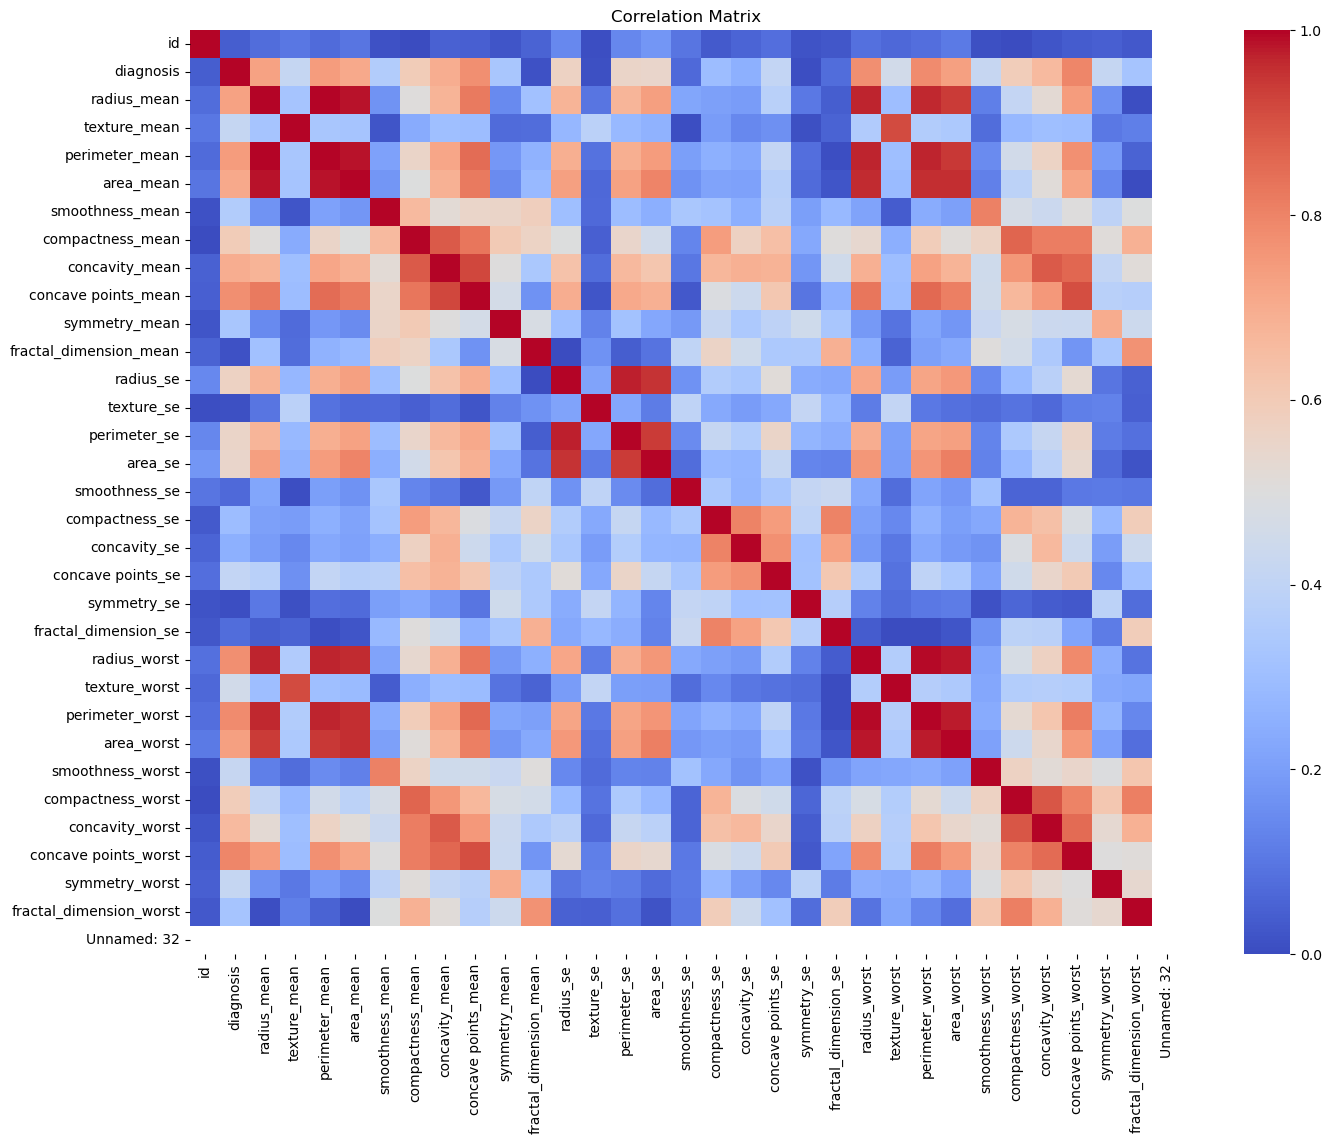

In [39]:
# Remove non-numeric columns, such as an ID column
numeric_df = df.select_dtypes(include="number")

# Calculate absolute correlations
corr_matrix = numeric_df.corr().abs()

# Plot the correlation matrix
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    vmin=0,
    vmax=1
)

plt.title("Correlation Matrix")
plt.show()

In [40]:
diagnosis_corr = (
    numeric_df.corr()["diagnosis"]
    .drop("diagnosis")
)

print(diagnosis_corr.sort_values())

smoothness_se             -0.067016
fractal_dimension_mean    -0.012838
texture_se                -0.008303
symmetry_se               -0.006522
id                         0.039769
fractal_dimension_se       0.077972
concavity_se               0.253730
compactness_se             0.292999
fractal_dimension_worst    0.323872
symmetry_mean              0.330499
smoothness_mean            0.358560
concave points_se          0.408042
texture_mean               0.415185
symmetry_worst             0.416294
smoothness_worst           0.421465
texture_worst              0.456903
area_se                    0.548236
perimeter_se               0.556141
radius_se                  0.567134
compactness_worst          0.590998
compactness_mean           0.596534
concavity_worst            0.659610
concavity_mean             0.696360
area_mean                  0.708984
radius_mean                0.730029
area_worst                 0.733825
perimeter_mean             0.742636
radius_worst               0

In [41]:
selected_features = [
    "concave points_worst",
    "smoothness_worst",
    "radius_worst",   
    "area_worst",
    "radius_mean",
    "area_se",
    "concavity_mean",
    "concavity_worst"
]

X = df[selected_features].copy()

y = df["diagnosis"].copy()

print("Selected features:", X.shape)
print("Target:", y.shape)

Selected features: (569, 8)
Target: (569,)


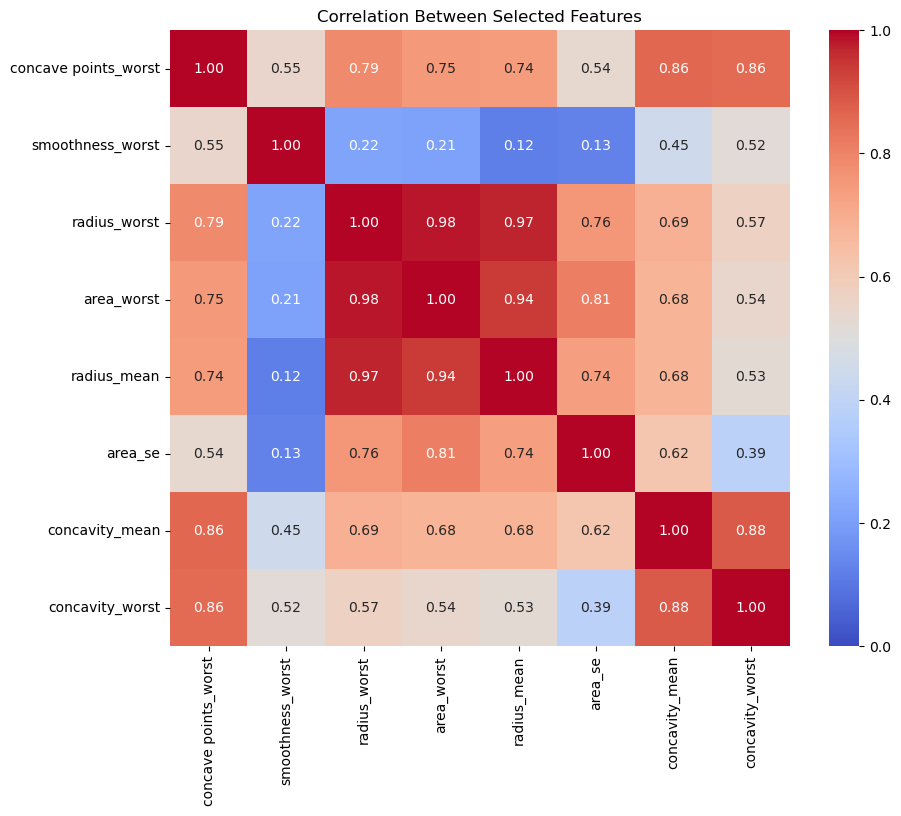

In [42]:
feature_corr = X.corr().abs()

plt.figure(figsize=(10, 8))

sns.heatmap(
    feature_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=0,
    vmax=1
)

plt.title("Correlation Between Selected Features")
plt.show()

In [43]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (455, 8)
X_test: (114, 8)
y_train: (455,)
y_test: (114,)


In [45]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [46]:
model = LogisticRegression(random_state=42, max_iter=1000)

model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [47]:
y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9736842105263158

Confusion Matrix:
[[72  0]
 [ 3 39]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

